In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import scipy.stats as scipy_stats
rng = np.random.default_rng(67)

# Задание 1

Рассмотрим распределение Парето

$$
X\sim\operatorname{Pareto}(x_0,\beta)
$$

где $x_0>0$ и $\beta>0$

Плотность

$$
f(x)=
\begin{cases}
\dfrac{\beta x_0^\beta}{x^{\beta+1}} & x\geq x_0\\
0 & x<x_0
\end{cases}
$$

Функция распределения

$$
F(x)=
\begin{cases}
0 & x<x_0\\
1-\left(\dfrac{x_0}{x}\right)^\beta & x\geq x_0
\end{cases}
$$

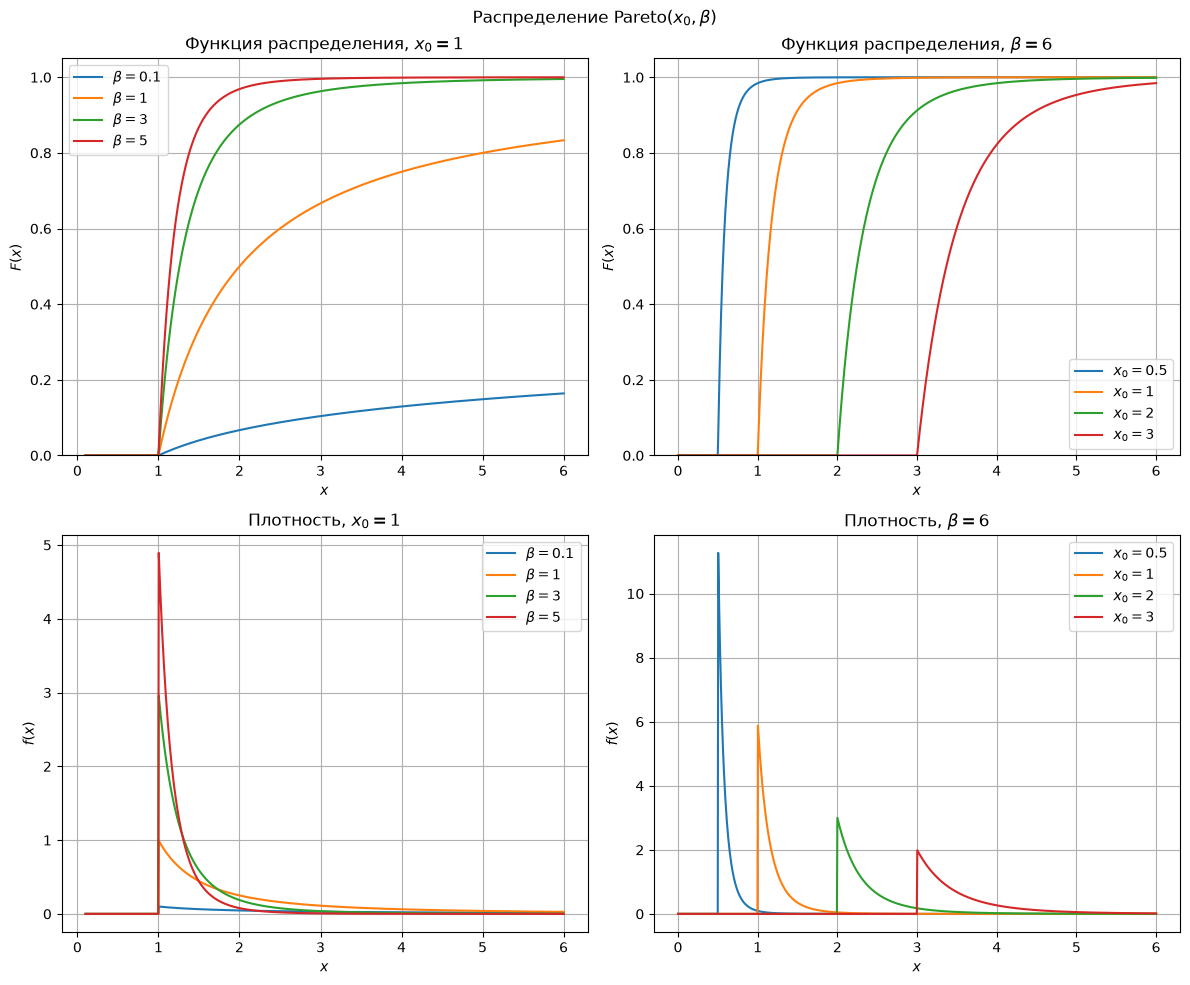

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

x_grid_beta = np.linspace(0.1, 6, 1000)
beta_values = [0.1, 1, 3, 5]

x_grid_x0 = np.linspace(0, 6, 1000)
x0_values = [0.5, 1, 2, 3]

for beta_value in beta_values:
    axes[0, 0].plot(
        x_grid_beta,
        scipy_stats.pareto.cdf(x_grid_beta, b=beta_value, scale=1),
        label=rf"$\beta={beta_value}$"
    )

axes[0, 0].set_title(r"Функция распределения, $x_0=1$")
axes[0, 0].set_xlabel("$x$")
axes[0, 0].set_ylabel(r"$F(x)$")
axes[0, 0].set_ylim(0, 1.05)
axes[0, 0].grid()
axes[0, 0].legend()

for x0_value in x0_values:
    axes[0, 1].plot(
        x_grid_x0,
        scipy_stats.pareto.cdf(x_grid_x0, b=6, scale=x0_value),
        label=rf"$x_0={x0_value}$"
    )

axes[0, 1].set_title(r"Функция распределения, $\beta=6$")
axes[0, 1].set_xlabel("$x$")
axes[0, 1].set_ylabel(r"$F(x)$")
axes[0, 1].set_ylim(0, 1.05)
axes[0, 1].grid()
axes[0, 1].legend()

for beta_value in beta_values:
    axes[1, 0].plot(
        x_grid_beta,
        scipy_stats.pareto.pdf(x_grid_beta, b=beta_value, scale=1),
        label=rf"$\beta={beta_value}$"
    )

axes[1, 0].set_title(r"Плотность, $x_0=1$")
axes[1, 0].set_xlabel("$x$")
axes[1, 0].set_ylabel(r"$f(x)$")
axes[1, 0].grid()
axes[1, 0].legend()

for x0_value in x0_values:
    axes[1, 1].plot(
        x_grid_x0,
        scipy_stats.pareto.pdf(x_grid_x0, b=6, scale=x0_value),
        label=rf"$x_0={x0_value}$"
    )

axes[1, 1].set_title(r"Плотность, $\beta=6$")
axes[1, 1].set_xlabel("$x$")
axes[1, 1].set_ylabel(r"$f(x)$")
axes[1, 1].grid()
axes[1, 1].legend()

plt.suptitle(r"Распределение $\operatorname{Pareto}(x_0,\beta)$")
plt.tight_layout()
plt.show()

Для распределения Парето $k$-й момент существует только при

$$
\beta>k
$$

и в этом случае

$$
\mathbb E[X^k]
=
\frac{\beta x_0^k}{\beta-k}
$$

Поэтому далее будем рассматривать

$$
\boxed{
X\sim\operatorname{Pareto}(1,6)
}
$$

То есть

$$
x_0=1
\qquad
\beta=6
$$

Моменты

$$
\mathbb E[X]
=
\frac{\beta x_0}{\beta-1}
=
\frac65
$$

$$
\mathbb E[X^2]
=
\frac{\beta x_0^2}{\beta-2}
=
\frac32
$$

$$
\mathbb E[X^3]
=
\frac{\beta x_0^3}{\beta-3}
=
2
$$

$$
\mathbb E[X^4]
=
\frac{\beta x_0^4}{\beta-4}
=
3
$$

Дисперсия

$$
\operatorname{Var}(X)
=
\mathbb E[X^2]-(\mathbb E[X])^2
=
\frac32-\frac{36}{25}
=
\boxed{\frac3{50}}
$$

$$
\sigma
=
\sqrt{\frac3{50}}
$$


In [3]:
x0 = 1.0
beta = 6.0

EXPERIMENTS_COUNT = 10_067
n_values = [10, 67, 567, 1067]

mu = beta * x0 / (beta - 1)
sigma2 = beta * x0**2 / ((beta - 1)**2 * (beta - 2))
sigma = np.sqrt(sigma2)

x_grid = np.linspace(-4, 4, 1000)

def pareto_sample(size):
    return x0 * (1 + rng.pareto(beta, size=size))


## Выборочное среднее

Пусть

$$
X_1,\ldots,X_n
\overset{iid}{\sim}
\operatorname{Pareto}(1,6)
$$

$$
\overline X_n
=
\frac1n\sum_{i=1}^n X_i
$$

ЦПТ

$$
\frac{
\sqrt n(\overline X_n-\mathbb E[X])
}{
\sigma
}
\xrightarrow{d}
\mathcal N(0,1)
$$

У нас

$$
\mathbb E[X]=\frac65,
\qquad
\sigma^2=\frac3{50}
$$

$$
\boxed{
Z_n
=
\frac{
\sqrt n
\left(
\overline X_n-\frac65
\right)
}{
\sqrt{3/50}
}
\xrightarrow{d}
\mathcal N(0,1)
}
$$

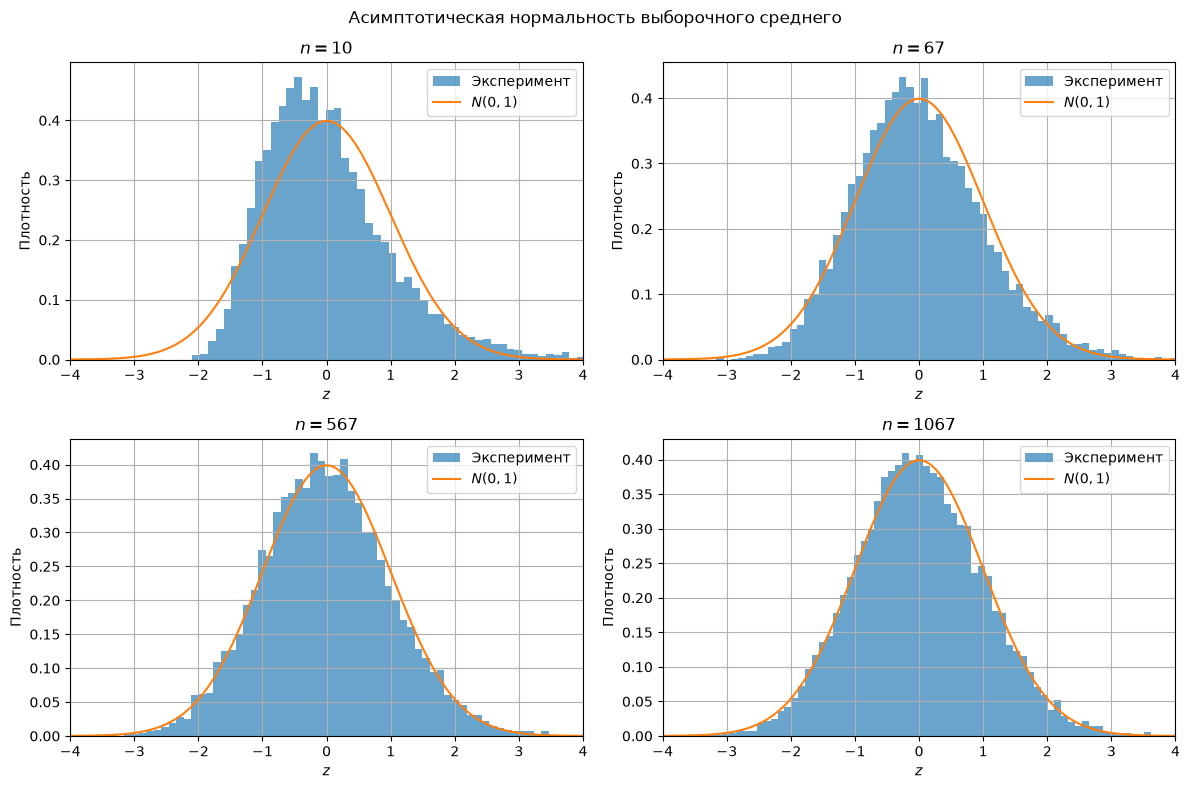

,n,Среднее,Дисперсия,Медиана
0,10,0.009757,1.000626,-0.143387
1,67,0.002868,0.997598,-0.064445
2,567,-0.010790,1.005811,-0.040269
3,1067,-0.002587,0.993846,-0.026807


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

statistics_mean = []

for ax, n in zip(axes.flat, n_values):
    z = np.empty(EXPERIMENTS_COUNT)

    for i in range(EXPERIMENTS_COUNT):
        x = pareto_sample(n)
        z[i] = np.sqrt(n) * (x.mean() - mu) / sigma

    ax.hist(z, bins=67, density=True, alpha=0.67, label="Эксперимент")
    ax.plot(x_grid, scipy_stats.norm.pdf(x_grid), label="$N(0,1)$")

    ax.set_title(f"$n={n}$")
    ax.set_xlabel("$z$")
    ax.set_ylabel("Плотность")
    ax.set_xlim(-4, 4)
    ax.grid()
    ax.legend()

    statistics_mean.append({
        "n": n,
        "Среднее": z.mean(),
        "Дисперсия": z.var(ddof=1),
        "Медиана": np.median(z)
    })

plt.suptitle(r"Асимптотическая нормальность выборочного среднего")
plt.tight_layout()
plt.show()

pd.DataFrame(statistics_mean)


## Выборочная дисперсия

Пусть

$$
S_n^2
=
\frac1n
\sum_{i=1}^n
(X_i-\overline X_n)^2
$$

ЦПТ + дельта-методу

$$
\sqrt n
\left(
S_n^2-\sigma^2
\right)
\xrightarrow{d}
\mathcal N
\left(
0,
\mu_4-\sigma^4
\right)
$$

где

$$
\mu_4
=
\mathbb E
\left[
(X-\mathbb E[X])^4
\right]
$$

$$
\mu_4
=
\mathbb E[X^4]
-4\mathbb E[X]\mathbb E[X^3]
+6(\mathbb E[X])^2\mathbb E[X^2]
-3(\mathbb E[X])^4
$$

У нас

$$
\mathbb E[X]=\frac65,
\qquad
\mathbb E[X^2]=\frac32,
\qquad
\mathbb E[X^3]=2,
\qquad
\mathbb E[X^4]=3
$$

$$
\mu_4
=
3
-4\cdot\frac65\cdot2
+6\left(\frac65\right)^2\frac32
-3\left(\frac65\right)^4
=
\boxed{\frac{87}{625}}
$$

$$
\sigma^2=\frac3{50}
$$

$$
\mu_4-\sigma^4
=
\frac{87}{625}
-\left(\frac3{50}\right)^2
=
\boxed{\frac{339}{2500}}
$$

$$
\boxed{
Z_n
=
\frac{
\sqrt n
\left(
S_n^2-\frac3{50}
\right)
}{
\sqrt{339/2500}
}
\xrightarrow{d}
\mathcal N(0,1)
}
$$


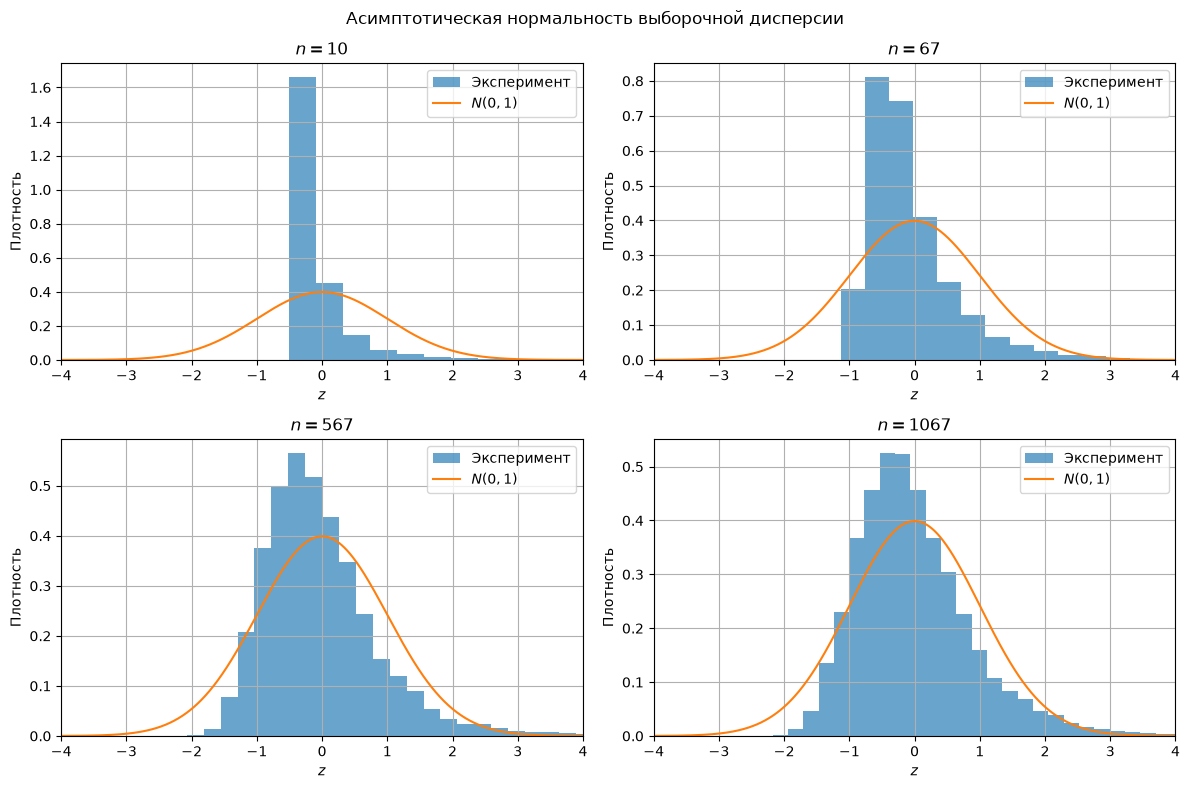

,n,Среднее,Дисперсия,Медиана
0,10,-0.056560,0.642369,-0.265564
1,67,-0.032298,0.869687,-0.240716
2,567,-0.003344,0.966825,-0.159793
3,1067,0.007784,0.959974,-0.140810


In [5]:
m1 = beta * x0 / (beta - 1)
m2 = beta * x0**2 / (beta - 2)
m3 = beta * x0**3 / (beta - 3)
m4 = beta * x0**4 / (beta - 4)

mu4 = m4 - 4 * m1 * m3 + 6 * m1**2 * m2 - 3 * m1**4
tau2_var = mu4 - sigma2**2

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

statistics_var = []

for ax, n in zip(axes.flat, n_values):
    z = np.empty(EXPERIMENTS_COUNT)

    for i in range(EXPERIMENTS_COUNT):
        x = pareto_sample(n)
        s2 = np.var(x, ddof=0)
        z[i] = np.sqrt(n) * (s2 - sigma2) / np.sqrt(tau2_var)

    ax.hist(z, bins=67, density=True, alpha=0.67, label="Эксперимент")
    ax.plot(x_grid, scipy_stats.norm.pdf(x_grid), label="$N(0,1)$")

    ax.set_title(f"$n={n}$")
    ax.set_xlabel("$z$")
    ax.set_ylabel("Плотность")
    ax.set_xlim(-4, 4)
    ax.grid()
    ax.legend()

    statistics_var.append({
        "n": n,
        "Среднее": z.mean(),
        "Дисперсия": z.var(ddof=1),
        "Медиана": np.median(z)
    })

plt.suptitle(r"Асимптотическая нормальность выборочной дисперсии")
plt.tight_layout()
plt.show()

pd.DataFrame(statistics_var)


## Выборочная медиана

Для теоритической медианы $m$

$$
F(m)=\frac12
$$

$$
1-
\left(
\frac{x_0}{m}
\right)^\beta
=
\frac12
$$

$$
\left(
\frac{x_0}{m}
\right)^\beta
=
\frac12
$$

$$
\boxed{
m=x_0 2^{1/\beta}
}
$$

У нас

$$
\boxed{
m=2^{1/6}
}
$$

Для выборочной медианы $\widehat m_n$ 

$$
\sqrt n
(\widehat m_n-m)
\xrightarrow{d}
\mathcal N
\left(
0,
\frac{1}{4f(m)^2}
\right)
$$

$$
f(m)
=
\frac{\beta x_0^\beta}{m^{\beta+1}}
$$

$$
f(m)
=
\frac{\beta}{x_0 2^{1+1/\beta}}
$$

$$
\frac{1}{4f(m)^2}
=
\frac{x_0^2 2^{2/\beta}}{\beta^2}
=
\frac{m^2}{\beta^2}
$$

$$
\boxed{
\frac{
\sqrt n(\widehat m_n-m)
}{
m/\beta
}
\xrightarrow{d}
\mathcal N(0,1)
}
$$


$$
\boxed{
Z_n
=
\frac{
\sqrt n
\left(
\widehat m_n-2^{1/6}
\right)
}{
2^{1/6}/6
}
\xrightarrow{d}
\mathcal N(0,1)
}
$$


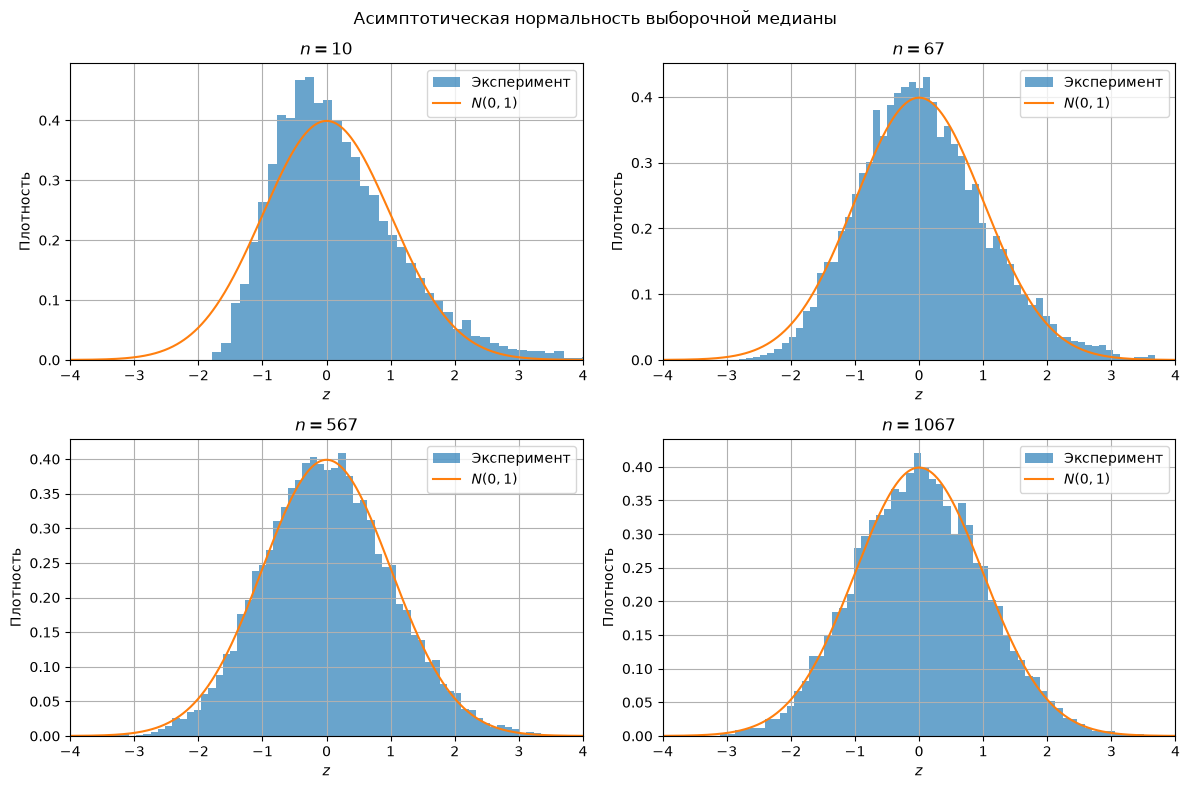

,n,Среднее,Дисперсия,Медиана
0,10,0.189699,1.033010,0.026391
1,67,0.064278,0.999575,0.000236
2,567,0.025385,0.988539,0.000236
3,1067,0.015892,1.006415,-0.000685


In [6]:
median = x0 * 2 ** (1 / beta)

f_median = (
    beta * x0**beta
    / median ** (beta + 1)
)

tau_median = 1 / (2 * f_median)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

statistics_median = []

for ax, n in zip(axes.flat, n_values):
    z = np.empty(EXPERIMENTS_COUNT)

    for i in range(EXPERIMENTS_COUNT):
        x = pareto_sample(n)
        sample_median = np.median(x)
        z[i] = np.sqrt(n) * (sample_median - median) / tau_median

    ax.hist(z, bins=67, density=True, alpha=0.67, label="Эксперимент")
    ax.plot(x_grid, scipy_stats.norm.pdf(x_grid), label="$N(0,1)$")

    ax.set_title(f"$n={n}$")
    ax.set_xlabel("$z$")
    ax.set_ylabel("Плотность")
    ax.set_xlim(-4, 4)
    ax.grid()
    ax.legend()

    statistics_median.append({
        "n": n,
        "Среднее": z.mean(),
        "Дисперсия": z.var(ddof=1),
        "Медиана": np.median(z)
    })

plt.suptitle(r"Асимптотическая нормальность выборочной медианы")
plt.tight_layout()
plt.show()

pd.DataFrame(statistics_median)


## Порядковые статистики

Пусть

$$
X_{(1)}
\leq
X_{(2)}
\leq
\ldots
\leq
X_{(n)}
$$

По теореме об асимптотике крайнего члена вариационного ряда

$$
\boxed{
nF(X_{(k)})
\xrightarrow{d}
\Gamma(k,1)
}
$$

$$
\boxed{
n
\left(
1-F(X_{(n+1-j)})
\right)
\xrightarrow{d}
\Gamma(j,1)
}
$$

У нас

$$
F(x)
=
1-
\left(
\frac{x_0}{x}
\right)^\beta
$$

$$
\boxed{
nF(X_{(k)})
=
n
\left[
1-
\left(
\frac{x_0}{X_{(k)}}
\right)^\beta
\right]
}
$$

$$
\boxed{
n
\left(
1-F(X_{(n+1-j)})
\right)
=
n
\left(
\frac{x_0}{X_{(n+1-j)}}
\right)^\beta
}
$$

Исходя из Громоздин Александр

$$
k=4,
\qquad
j=1
$$


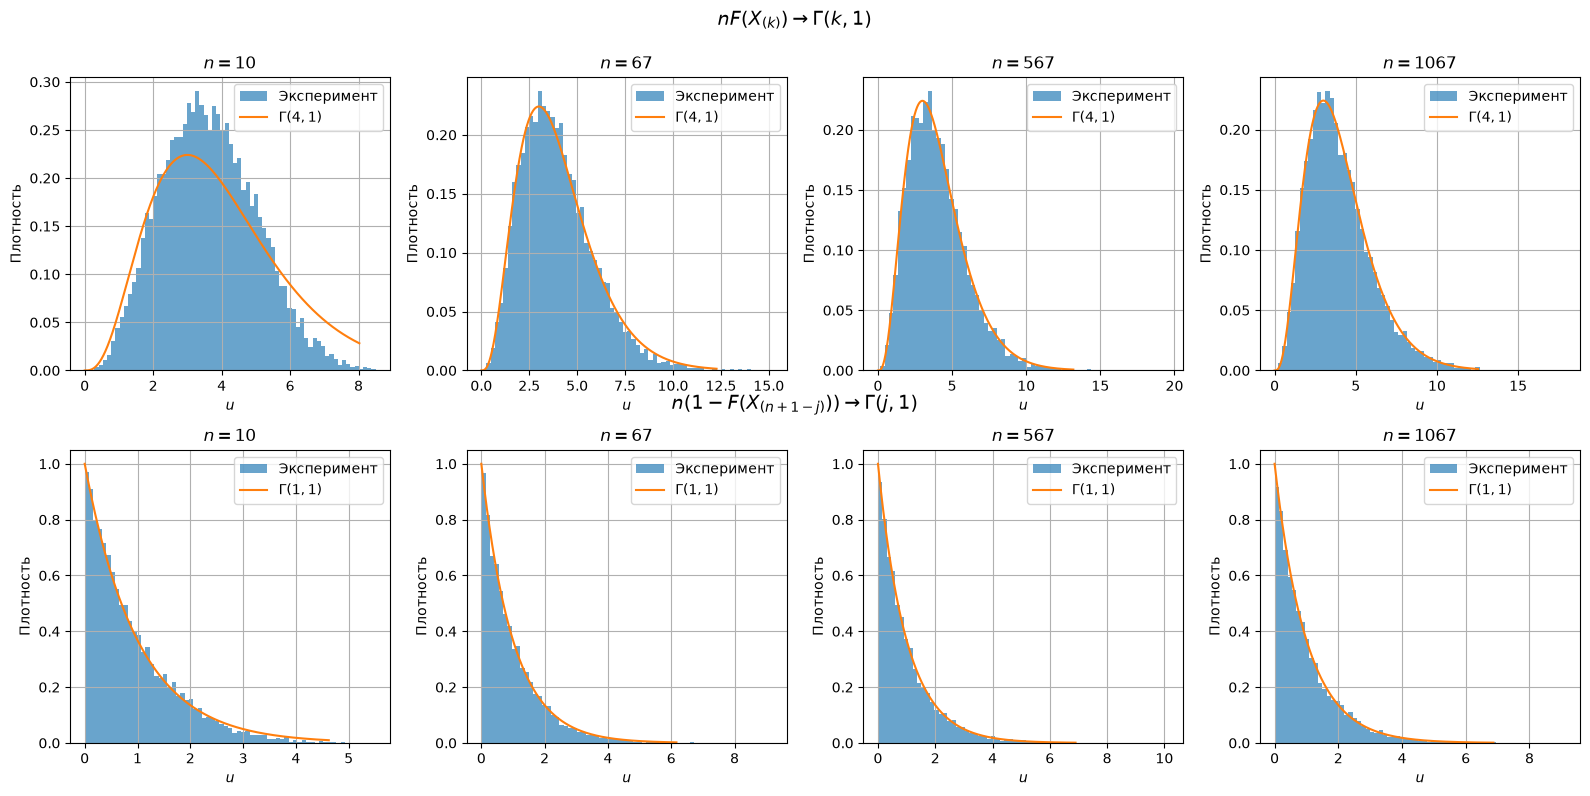

,n,E(U1),Var(U1),Med(U1),E(U2),Var(U2),Med(U2)
0,10,3.645655,1.906551,3.570985,0.908497,0.669924,0.669721
1,67,3.949204,3.555226,3.686904,0.971276,0.889173,0.687315
2,567,3.995281,3.897766,3.683386,0.997774,1.006376,0.688366
3,1067,3.979042,3.914431,3.641189,1.016142,1.044133,0.702756


In [7]:
k = 4
j = 1

fig, axes = plt.subplots(2, len(n_values), figsize=(16, 8))

statistics_order = []

for col, n in enumerate(n_values):
    u1 = np.empty(EXPERIMENTS_COUNT)
    u2 = np.empty(EXPERIMENTS_COUNT)

    for i in range(EXPERIMENTS_COUNT):
        x = pareto_sample(n)
        x.sort()

        x_k = x[k - 1]
        x_nj = x[n - j]

        u1[i] = n * (1 - (x0 / x_k) ** beta)
        u2[i] = n * (x0 / x_nj) ** beta

    x1 = np.linspace(0, np.quantile(u1, 0.999), 1000)
    x2 = np.linspace(0, np.quantile(u2, 0.999), 1000)

    axes[0, col].hist(
        u1,
        bins=67,
        density=True,
        alpha=0.67,
        label="Эксперимент"
    )

    axes[0, col].plot(
        x1,
        scipy_stats.gamma.pdf(x1, a=k, scale=1),
        label=rf"$\Gamma({k},1)$"
    )

    axes[0, col].set_title(f"$n={n}$")
    axes[0, col].set_xlabel("$u$")
    axes[0, col].set_ylabel("Плотность")
    axes[0, col].grid()
    axes[0, col].legend()

    axes[1, col].hist(
        u2,
        bins=67,
        density=True,
        alpha=0.67,
        label="Эксперимент"
    )

    axes[1, col].plot(
        x2,
        scipy_stats.gamma.pdf(x2, a=j, scale=1),
        label=rf"$\Gamma({j},1)$"
    )

    axes[1, col].set_title(f"$n={n}$")
    axes[1, col].set_xlabel("$u$")
    axes[1, col].set_ylabel("Плотность")
    axes[1, col].grid()
    axes[1, col].legend()

    statistics_order.append({
        "n": n,
        "E(U1)": u1.mean(),
        "Var(U1)": u1.var(ddof=1),
        "Med(U1)": np.median(u1),
        "E(U2)": u2.mean(),
        "Var(U2)": u2.var(ddof=1),
        "Med(U2)": np.median(u2)
    })

fig.text(
    0.5,
    0.97,
    r"$nF(X_{(k)}) \rightarrow \Gamma(k,1)$",
    ha="center",
    fontsize=14
)

fig.text(
    0.5,
    0.49,
    r"$n(1-F(X_{(n+1-j)})) \rightarrow \Gamma(j,1)$",
    ha="center",
    fontsize=14
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

pd.DataFrame(statistics_order)

## Вывод

Для распределения

$$
X\sim\operatorname{Pareto}(1,6)
$$

Из графиков подтверждена асимптотическая нормальность выборочного среднего

$$
\frac{
\sqrt n
\left(
\overline X_n-\frac65
\right)
}{
\sqrt{3/50}
}
\xrightarrow{d}
\mathcal N(0,1)
$$

выборочной дисперсии

$$
\frac{
\sqrt n
\left(
S_n^2-\frac3{50}
\right)
}{
\sqrt{339/2500}
}
\xrightarrow{d}
\mathcal N(0,1)
$$

и выборочной медианы

$$
\frac{
\sqrt n
\left(
\widehat m_n-2^{1/6}
\right)
}{
2^{1/6}/6
}
\xrightarrow{d}
\mathcal N(0,1)
$$

Также экспериментально подтверждены предельные распределения

$$
nF(X_{(k)})
\xrightarrow{d}
\Gamma(k,1)
$$

$$
n
\left(
1-F(X_{(n+1-j)})
\right)
\xrightarrow{d}
\Gamma(j,1)
$$


# Задание 2

Рассмотрим модель с выбросами

$$
F(x)
=
(1-\varepsilon)F_{\mathcal N(\mu,\sigma^2)}(x)
+
\varepsilon F_{\mathcal N(\mu,\tau^2)}(x)
$$

где $ \tau^2 \gg \sigma^2 $ то есть $ \tau^2 $ на порядок больше чем $ \sigma^2 $

Каждое наблюдение с вероятностью $1 - \varepsilon$ берётся из распределения

$$
\mathcal N(\mu,\sigma^2)
$$

и с вероятностью $\varepsilon$ из распределения

$$
\mathcal N(\mu,\tau^2)
$$

Именно второе распределение отвечает за выбросы, не смотря на то что мат ожидание у обоих одинаковое, дисперсия у него на порядок больше то есть систематическая ошибка исходного распределения сильно зависит от частоты выпадения шума

### Математическое ожидание $X$

Положим

$$
B\sim\operatorname{Bern}(\varepsilon)
$$

то есть

$$
P(B=1)=\varepsilon
\qquad
P(B=0)=1-\varepsilon
$$

Также положим

$$
Y\sim\mathcal N(\mu,\sigma^2)
$$

$$
Z\sim\mathcal N(\mu,\tau^2)
$$

Тогда 

$$ X=(1-B)Y+BZ $$

$$X\mid B=0\sim\mathcal N(\mu,\sigma^2)$$

$$X\mid B=1\sim\mathcal N(\mu,\tau^2)$$

По полному мат ожиданию

$$
\mathbb E[X]
=
\mathbb E\left[\mathbb E[X\mid B]\right] = P(B=0)\mathbb E[X\mid B=0] + P(B=1)\mathbb E[X\mid B=1] = (1-\varepsilon)\mu+\varepsilon\mu = \mu
$$

Итого

$$
\boxed{\mathbb E[X]=\mu}
$$

То есть мы получили что добавление выбросов не изменяет мат ожидание

### Дисперсия $X$

$$
\operatorname{Var}(X)
=
\mathbb E[(X-\mathbb E[X])^2]
=
\mathbb E[(X-\mu)^2]
$$

По полному мат ожиданию

$$
\operatorname{Var}(X)=\mathbb E\left[\mathbb E\left[(X-\mu)^2\mid B\right]\right]=P(B=0)\mathbb E\left[(X-\mu)^2\mid B=0\right]+P(B=1)\mathbb E\left[(X-\mu)^2\mid B=1\right]
$$

При $B=0$

$$
\mathbb E[(X-\mu)^2\mid B=0]
=
\sigma^2
$$

При $B=1$

$$
\mathbb E[(X-\mu)^2\mid B=1] = \tau^2
$$

Итого

$$
\boxed{ \operatorname{Var}(X) = (1-\varepsilon)\sigma^2+\varepsilon\tau^2 }
$$

### Дисперсия выборочного среднего

$$
\overline X=\frac1n\sum_{i=1}^nX_i
$$

Тогда

$$
\begin{aligned}
\operatorname{Var}(\overline X)
=
\operatorname{Var}
\left(
\frac1n\sum_{i=1}^nX_i
\right)
=
\frac1{n^2}
\operatorname{Var}
\left(
\sum_{i=1}^nX_i
\right)
=
\frac1{n^2}
\sum_{i=1}^n\operatorname{Var}(X_i)
=
\frac1n\operatorname{Var}(X)
\end{aligned}
$$

Следовательно

$$
\boxed{
\operatorname{Var}(\overline X)
=
\frac{(1-\varepsilon)\sigma^2+\varepsilon\tau^2}{n}
}
$$

и

$$
\boxed{
n\operatorname{Var}(\overline X)
=
(1-\varepsilon)\sigma^2+\varepsilon\tau^2
}
$$

### Медиана распределения

Обе компоненты смеси симметричны относительно $\mu$ поэтому

$$
F_{\mathcal N(\mu,\sigma^2)}(\mu)=\frac12
$$

и

$$
F_{\mathcal N(\mu,\tau^2)}(\mu)=\frac12
$$

Следовательно

$$
F(\mu)
=
(1-\varepsilon)\frac12
+
\varepsilon\frac12
=
\frac12
$$

Значит медиана распределения равна

$$
\boxed{m=\mu}
$$

Обозначим выборочную медиану через

$$
\widehat m_n=\operatorname{Med}(X_1,\ldots,X_n)
$$

### Асимптотическая дисперсия выборочной медианы

Для выборочной квантили порядка $p$ верна теорема

$$
\sqrt n(\widehat q_{p,n}-q_p)
\xrightarrow{d}
\mathcal N
\left(
0,
\frac{p(1-p)}{f(q_p)^2}
\right)
$$

Для медианы

$$
p=\frac12
\qquad
q_p=m=\mu
$$

поэтому

$$
\sqrt n(\widehat m_n-m)
\xrightarrow{d}
\mathcal N
\left(
0,
\frac1{4f(m)^2}
\right)
$$

Следовательно

$$
\operatorname{Var}(\widehat m_n)
\sim
\frac1{4nf(m)^2}
$$

Плотность распределения

$$
f(x)
=
(1-\varepsilon)f_{\mathcal N(\mu,\sigma^2)}(x)
+
\varepsilon f_{\mathcal N(\mu,\tau^2)}(x)
$$

Для нормального распределения

$$
f_{\mathcal N(\mu,s^2)}(x)
=
\frac1{s\sqrt{2\pi}}
\exp
\left(
-\frac{(x-\mu)^2}{2s^2}
\right)
$$

В точке $x=m=\mu$

$$
f_{\mathcal N(\mu,\sigma^2)}(m)
=
\frac1{\sigma\sqrt{2\pi}}
$$

$$
f_{\mathcal N(\mu,\tau^2)}(m)
=
\frac1{\tau\sqrt{2\pi}}
$$

Поэтому

$$
f(m)
=
\frac1{\sqrt{2\pi}}
\left(
\frac{1-\varepsilon}{\sigma}
+
\frac{\varepsilon}{\tau}
\right)
$$

Подставим $f(m)$

$$
\begin{aligned}
\operatorname{Var}(\widehat m_n)
&\sim
\frac1{4nf(m)^2}
\\
&=
\frac1{
4n
\frac1{2\pi}
\left(
\frac{1-\varepsilon}{\sigma}
+
\frac{\varepsilon}{\tau}
\right)^2
}
\\
&=
\frac{\pi}{
2n
\left(
\frac{1-\varepsilon}{\sigma}
+
\frac{\varepsilon}{\tau}
\right)^2
}
\end{aligned}
$$

Итого

$$
\boxed{
n\operatorname{Var}(\widehat m_n)
\sim
\frac{\pi}{
2
\left(
\frac{1-\varepsilon}{\sigma}
+
\frac{\varepsilon}{\tau}
\right)^2
}
}
$$



## Эксперимент

Зафиксируем параметры

$$
\mu=0
\qquad
\sigma=1
\qquad
\tau=10
\qquad
\varepsilon=0.05
$$

Возьмём объём выборки

$$
n=100
$$

Сгенерируем $10000$ независимых выборок объёма $n$ и для каждой вычислим выборочное среднее $\overline X_n$ и выборочную медиану $\widehat m_n$

Построим гистограммы распределений полученных статистик и сравним их экспериментальные дисперсии с теоретическими значениями

Для выборочного среднего используем точную формулу дисперсии а для выборочной медианы асимптотическую


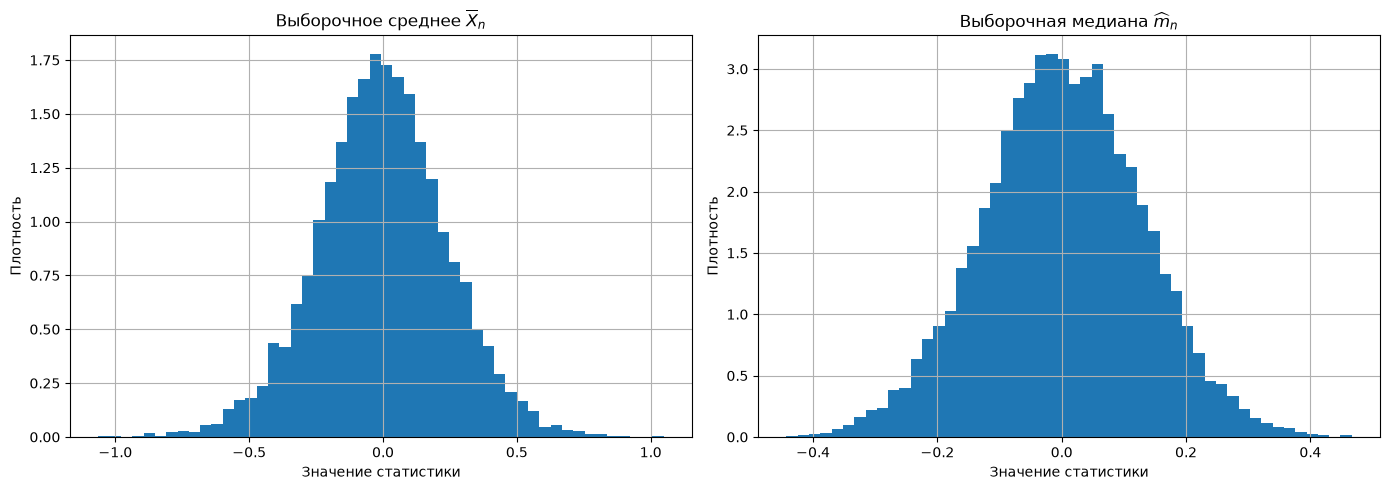

Выборочное среднее:
Теоретическая дисперсия 0.059500000000000004
Экспериментальная дисперсия 0.05856807393961723
Экспериментальное среднее -0.003968342194793082
Медиана значений статистики -0.005099778366200177

Выборочная медиана:
Асимптотическая дисперсия 0.0172231718077344
Экспериментальная дисперсия 0.01647335022579498
Экспериментальное среднее 0.001448237304216278
Медиана значений статистики 0.0010778119023357917


In [13]:

mix_mu = 0
mix_sigma = 1
mix_tau = 10
mix_eps = 0.05

mix_n = 100
mix_experiments = 10_000

B = rng.random((mix_experiments, mix_n)) < mix_eps

scales = np.where(B, mix_tau, mix_sigma)
samples = rng.normal(mix_mu, scales)

means = np.mean(samples, axis=1)
medians = np.median(samples, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(means, bins=50, density=True)
axes[0].set_title(r"Выборочное среднее $\overline{X}_n$")
axes[0].set_xlabel("Значение статистики")
axes[0].set_ylabel("Плотность")
axes[0].grid()

axes[1].hist(medians, bins=50, density=True)
axes[1].set_title(r"Выборочная медиана $\widehat{m}_n$")
axes[1].set_xlabel("Значение статистики")
axes[1].set_ylabel("Плотность")
axes[1].grid()

plt.tight_layout()
plt.show()

var_mean_theoretical = (
    (1 - mix_eps) * mix_sigma**2 + mix_eps * mix_tau**2
) / mix_n

var_median_theoretical = np.pi / (
    2 * mix_n * ((1 - mix_eps) / mix_sigma + mix_eps / mix_tau)**2
)

print("Выборочное среднее:")
print("Теоретическая дисперсия", var_mean_theoretical)
print("Экспериментальная дисперсия", np.var(means, ddof=1))
print("Экспериментальное среднее", np.mean(means))
print("Медиана значений статистики", np.median(means))

print()

print("Выборочная медиана:")
print("Асимптотическая дисперсия", var_median_theoretical)
print("Экспериментальная дисперсия", np.var(medians, ddof=1))
print("Экспериментальное среднее", np.mean(medians))
print("Медиана значений статистики", np.median(medians))


Из графика видно что при $\varepsilon=0$ выборочное среднее имеет меньшую дисперсию однако при увеличении $\varepsilon$ дисперсия среднего быстро растёт из-за большого значения $\tau^2$ в то время как медиана значительно слабее зависит от выбросов

## Эксперимент (распределния выборочного среднего и выборочной медианы)

Положим

$$
\mu=0
\qquad
\sigma=1
\qquad
\tau=10
\qquad
\varepsilon=0.05
$$

Возьмём

$$
n=100
$$

и сгенерируем $10000$ выборок для каждой из которых вычислим выборочное среднее и выборочную медиану

mu = 0
sigma = 1
tau = 10
eps = 0.05

n = 100
experiments = 10_000

B = rng.random((experiments, n)) < eps

scales = np.where(B, tau, sigma)

samples = rng.normal(mu, scales)

means = np.mean(samples, axis=1)
medians = np.median(samples, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(means, bins=50, density=True)
axes[0].set_title("Выборочное среднее")
axes[0].grid()

axes[1].hist(medians, bins=50, density=True)
axes[1].set_title("Выборочная медиана")
axes[1].grid()

plt.tight_layout()
plt.show()

var_mean_theoretical = (
    (1 - eps) * sigma**2 + eps * tau**2
) / n

var_median_theoretical = np.pi / (
    2 * n * ((1 - eps) / sigma + eps / tau)**2
)

print("Выборочное среднее:")
print("Теоретическая дисперсия", var_mean_theoretical)
print("Экспериментальная дисперсия", np.var(means, ddof=1))
print("Мат ожидание", np.mean(means))
print("Медиана", np.median(means))

print()

print("Выборочная медиана:")
print("Теоретическая дисперсия", var_median_theoretical)
print("Экспериментальная дисперсия", np.var(medians, ddof=1))
print("Мат ожидание", np.mean(medians))
print("Медиана", np.median(medians))


## Вывод

Для выборочного среднего получили точную формулу дисперсии

$$
\boxed{
\operatorname{Var}(\overline X_n)
=
\frac{(1-\varepsilon)\sigma^2+\varepsilon\tau^2}{n}
}
$$

Для выборочной медианы получили асимптотическую формулу дисперсии

$$
\boxed{
\operatorname{Var}(\widehat m_n)
\sim
\frac{\pi}{
2n
\left(
\frac{1-\varepsilon}{\sigma}
+
\frac{\varepsilon}{\tau}
\right)^2
}
}
$$

При отсутствии выбросов выборочное среднее обладает меньшей дисперсией чем выборочная медиана

При увеличении доли выбросов дисперсия выборочного среднего растёт значительно быстрее чем дисперсия выборочной медианы

Таким образом выборочная медиана является более устойчивой к выбросам оценкой параметра $\mu$


# Задание 3

Рассмотрим датасет Iris который содержит информацию о разных видах цветов ириса

В нём представлены три класса

<table>
<tr>
<td align="center">
<img src="data/setosa.png" width="250"><br>
<b>Setosa</b><br>
Ирис щетинистый
</td>

<td align="center">
<img src="data/versicolor.png" width="250"><br>
<b>Versicolor</b><br>
Ирис разноцветный
</td>

<td align="center">
<img src="data/virginica.png" width="250"><br>
<b>Virginica</b><br>
Ирис виргинский
</td>
</tr>
</table>

Положим

$$
X=\text{длина чашелистика}
$$

In [10]:
# %pip install scikit-learn
from sklearn.datasets import load_iris

iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)

df["class"] = [iris.target_names[i] for i in iris.target]

feature = "sepal length (cm)"

def statistics(x):
    return pd.Series({
        "Выборочное среднее": x.mean(),
        "Выборочная дисперсия": x.var(ddof=1),
        "Выборочное стандартное отклонение": x.std(ddof=1),
        "Минимум": x.min(),
        "Максимум": x.max(),
        "Первый квартиль": x.quantile(0.25),
        "Медиана": x.median(),
        "Третий квартиль": x.quantile(0.75),
        "Межквартильный размах (IQR)": x.quantile(0.75) - x.quantile(0.25)
    })

stats = pd.concat(
    [
        statistics(df[feature]).to_frame("Все"),
        df.groupby("class")[feature].apply(statistics).unstack().T
    ],
    axis=1
).T

stats

,Выборочное среднее,Выборочная дисперсия,Выборочное стандартное отклонение,Минимум,Максимум,Первый квартиль,Медиана,Третий квартиль,Межквартильный размах (IQR)
Все,5.843333,0.685694,0.828066,4.3,7.9,5.100,5.8,6.4,1.300
setosa,5.006000,0.124249,0.352490,4.3,5.8,4.800,5.0,5.2,0.400
versicolor,5.936000,0.266433,0.516171,4.9,7.0,5.600,5.9,6.3,0.700
virginica,6.588000,0.404343,0.635880,4.9,7.9,6.225,6.5,6.9,0.675


### Визуализация

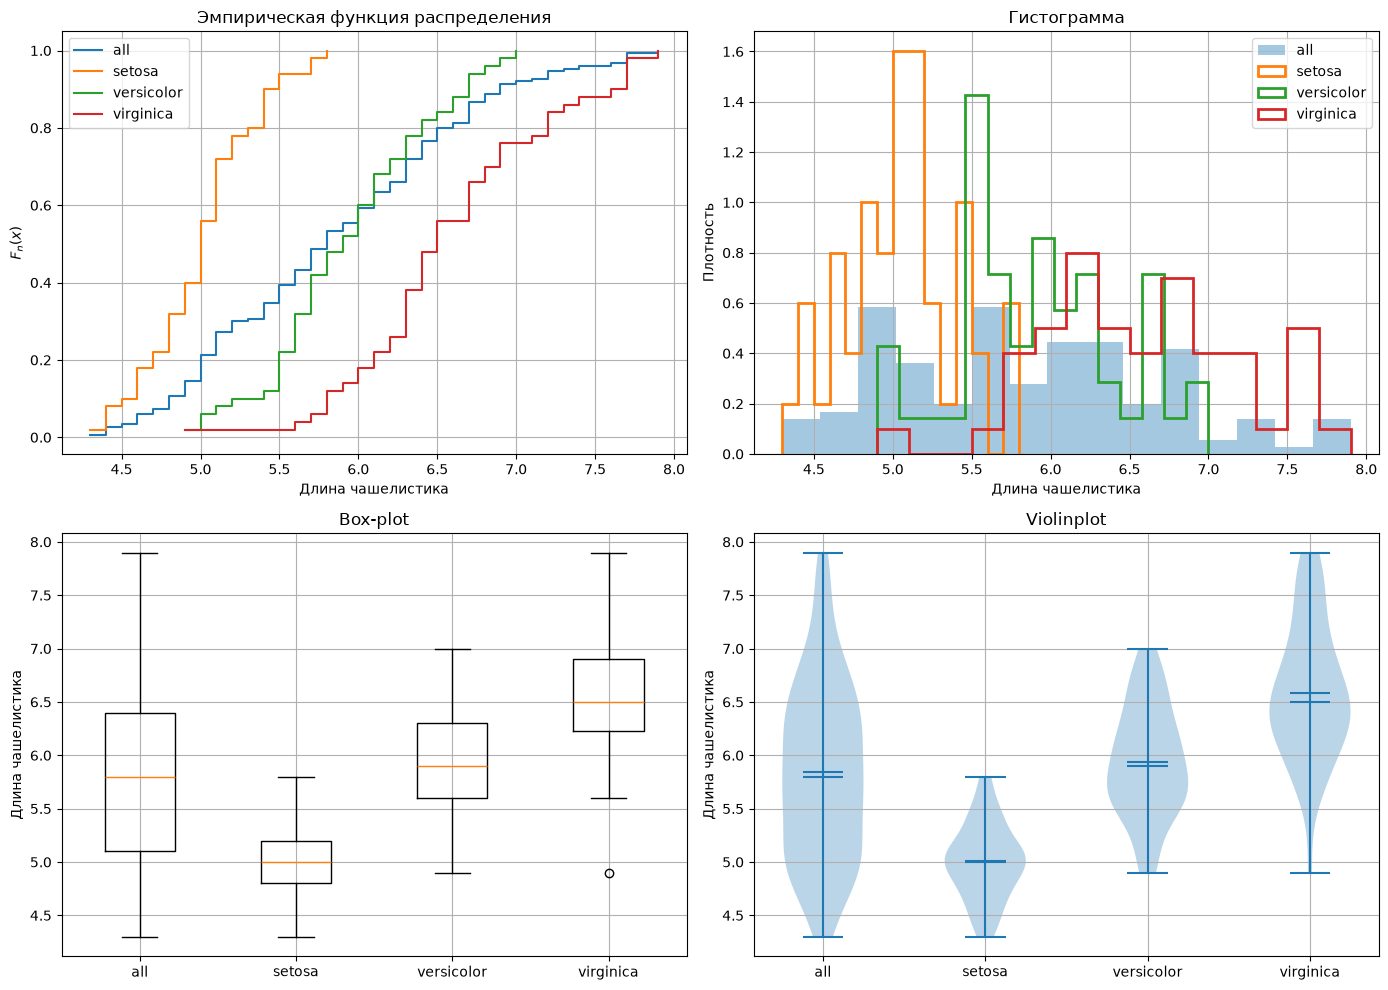

In [11]:
classes = iris.target_names

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

x = np.sort(df[feature].to_numpy())
y = np.arange(1, len(x) + 1) / len(x)

axes[0, 0].step(x, y, where="post", label="all")

for cls in classes:
    values = np.sort(df[df["class"] == cls][feature].to_numpy())
    ecdf = np.arange(1, len(values) + 1) / len(values)
    axes[0, 0].step(values, ecdf, where="post", label=cls)

axes[0, 0].set_title("Эмпирическая функция распределения")
axes[0, 0].set_xlabel("Длина чашелистика")
axes[0, 0].set_ylabel(r"$F_n(x)$")
axes[0, 0].grid()
axes[0, 0].legend()

axes[0, 1].hist(df[feature], bins=15, density=True, alpha=0.4, label="all")

for cls in classes:
    axes[0, 1].hist(
        df[df["class"] == cls][feature],
        bins=15,
        density=True,
        histtype="step",
        linewidth=2,
        label=cls
    )

axes[0, 1].set_title("Гистограмма")
axes[0, 1].set_xlabel("Длина чашелистика")
axes[0, 1].set_ylabel("Плотность")
axes[0, 1].grid()
axes[0, 1].legend()

box_data = [df[feature]] + [
    df[df["class"] == cls][feature]
    for cls in classes
]

labels = ["all"] + list(classes)

axes[1, 0].boxplot(box_data, tick_labels=labels)
axes[1, 0].set_title("Box-plot")
axes[1, 0].set_ylabel("Длина чашелистика")
axes[1, 0].grid()

axes[1, 1].violinplot(
    box_data,
    showmeans=True,
    showmedians=True
)

axes[1, 1].set_xticks(range(1, len(labels) + 1))
axes[1, 1].set_xticklabels(labels)
axes[1, 1].set_title("Violinplot")
axes[1, 1].set_ylabel("Длина чашелистика")
axes[1, 1].grid()

plt.tight_layout()
plt.show()

## Вывод

По описательным статистикам и графикам видно что распределения длины чашелистика различаются между классами

У класса setosa значения в среднем меньше

У класса virginica значения в среднем больше

Класс versicolor занимает промежуточное положение

При объединении классов разброс становится больше чем внутри отдельных классов

Box-plot и violinplot показывают различие положения и формы распределений между классами

Эмпирические функции распределения также заметно сдвинуты друг относительно друга

Таким образом длина чашелистика содержит информацию о классе цветка и может использоваться для различения классов